## log-ratio-plots-peptides-CalCurves
11.1.25

The classic log FC plotting notebook, for the yeast CalCurves MMCC dataset this time. What if I plot
only unimputed and Nettle here? This could be main text. And then maybe a version of the plot that
shows the plug-in methods could be supplemental. 

In [1]:
import pandas as pd
import numpy as np 
from scipy import stats
from tqdm import tqdm

import matplotlib.pyplot as plt
import seaborn as sns

# plotting templates
sns.set(context="talk", style="ticks") 
pal = sns.color_palette("tab10")

#### Configs

In [2]:
unimputed_path="../quant-reports/CalCurves-unimputed-report.csv"
cortado_path="../quant-reports/CalCurves-cortado-report.csv"
nettle_path="../quant-reports/CalCurves-nettle-report.csv"
#knn_plugin_report_path="../plugin-reports/CalCurves-knn-TIC-report.csv"
#mf_plugin_report_path="../plugin-reports/CalCurves-missforest-TIC-report.csv"

q_thresh_a100=0.1

#### Functions 

In [3]:
def average_replicates(report):
    """
    Just like previous, except that here we take the average across the three
    replicates instead of concatting. Also calcualtes the standard deviation across
    the three replicates and sets the averaged quant to NaN if it is greater than
    some specified threshold. 
    
    Parameters
    ----------
    report : `pandas.DataFrame`, 
        The Skyline quants report 
    std_thresh : float, 
        The threshold, in standard deviations, to use for determining whether or
        not to retain an averaged quant value 
        
    Returns
    ----------
    report_comb : `pandas.DataFrame`, 
    """
    colnames = ["A", "B", "C", "D", "E", "F", "G", "H", "I", "J", "K", "L", "M", "N"]
    comb_arr = []
    
    for i in range(0, report.shape[1], 3):
        colname1 = list(report.columns)[i]
        colname2 = list(report.columns)[i+1]
        colname3 = list(report.columns)[i+2]
    
        col1 = np.array(report[colname1])
        col2 = np.array(report[colname2])
        col3 = np.array(report[colname3])

        ave = np.nanmean([col1, col2, col3], axis=0)
        comb_arr.append(list(ave))
    
    report_comb = pd.DataFrame(comb_arr).T
    report_comb.columns = colnames 
 
    return report_comb

#### Read in and pre-process the quants reports 

In [4]:
to_drop = ["Protein Name", "Peptide Modified Sequence", "Precursor Charge"]
           
# Read in the three Skyline report csvs
unimputed_df = pd.read_csv(unimputed_path)
unimputed_df.index = unimputed_df["Peptide Modified Sequence"]
unimputed_df = unimputed_df.drop(columns=to_drop)

cortado_df = pd.read_csv(cortado_path)
cortado_df.index = cortado_df["Peptide Modified Sequence"]
cortado_df = cortado_df.drop(columns=to_drop)

nettle_df = pd.read_csv(nettle_path)
nettle_df.index = nettle_df["Peptide Modified Sequence"]
nettle_df = nettle_df.drop(columns=["Protein Name", "Peptide Modified Sequence"])

print(unimputed_df.shape)
print(cortado_df.shape)
print(nettle_df.shape)

(42093, 42)
(42011, 42)
(37362, 42)


#### Read in the plug-in imputed quants matrices 

In [5]:
# knn_df = pd.read_csv(knn_plugin_report_path, index_col=0)
# mf_df = pd.read_csv(mf_plugin_report_path, index_col=0)

# print(knn_df.shape)
# print(mf_df.shape)

#### Drop duplicates and sort 

In [6]:
# DROP DUPLICATES
unimputed_df = unimputed_df[~unimputed_df.index.duplicated(keep="first")]
cortado_df = cortado_df[~cortado_df.index.duplicated(keep="first")]
nettle_df = nettle_df[~nettle_df.index.duplicated(keep="first")]
#knn_df = knn_df[~knn_df.index.duplicated(keep="first")]
#mf_df = mf_df[~mf_df.index.duplicated(keep="first")]

# SORT 
unimputed_df = unimputed_df.loc[sorted(unimputed_df.index)]
cortado_df = cortado_df.loc[sorted(cortado_df.index)]
nettle_df = nettle_df.loc[sorted(nettle_df.index)]
#knn_df = knn_df.loc[sorted(knn_df.index)]
#mf_df = mf_df.loc[sorted(mf_df.index)]

print(unimputed_df.shape)
print(cortado_df.shape)
print(nettle_df.shape)
#print(knn_df.shape)
#print(mf_df.shape)

(33660, 42)
(33612, 42)
(33612, 42)


#### Handle the missing values

In [7]:
unimputed_df[unimputed_df == 0.0] = np.nan
unimputed_df[np.isinf(unimputed_df)] = np.nan

cortado_df[cortado_df == 0.0] = np.nan
cortado_df[np.isinf(cortado_df)] = np.nan

nettle_df[nettle_df == 0.0] = np.nan
nettle_df[np.isinf(nettle_df)] = np.nan

# knn_df[knn_df == 0.0] = np.nan
# knn_df[np.isinf(knn_df)] = np.nan

# mf_df[mf_df == 0.0] = np.nan
# mf_df[np.isinf(mf_df)] = np.nan

#### Get the missingness fractions 

In [8]:
unimputed_mvs = np.count_nonzero(np.isnan(unimputed_df))
unimputed_mv_frac = np.around(unimputed_mvs / unimputed_df.size, 2)

cortado_mvs = np.count_nonzero(np.isnan(cortado_df))
cortado_mv_frac = np.around(cortado_mvs / cortado_df.size, 2)

nettle_mvs = np.count_nonzero(np.isnan(nettle_df))
nettle_mv_frac = np.around(nettle_mvs / nettle_df.size, 2)

# knn_mvs = np.count_nonzero(np.isnan(knn_df))
# knn_mv_frac = np.around(knn_mvs / knn_df.size, 2)

# mf_mvs = np.count_nonzero(np.isnan(mf_df))
# mf_mv_frac = np.around(mf_mvs / mf_df.size, 2)

print(f"mv frac unimputed: {unimputed_mv_frac}")
print(f"mv frac cortado: {cortado_mv_frac}")
print(f"mv frac nettle: {nettle_mv_frac}")
#print(f"mv frac knn: {knn_mv_frac}")
#print(f"mv frac missforest: {mf_mv_frac}")

mv frac unimputed: 0.72
mv frac cortado: 0.4
mv frac nettle: 0.25


#### Subset to only the shared peptides 

In [9]:
inter = set.intersection(set(unimputed_df.index), set(cortado_df.index), set(nettle_df.index))

unimputed_df = unimputed_df.loc[list(inter)]
cortado_df = cortado_df.loc[list(inter)]
nettle_df = nettle_df.loc[list(inter)]
#knn_df = knn_df.loc[list(inter)]
#mf_df = mf_df.loc[list(inter)]

print(unimputed_df.shape)
print(cortado_df.shape)
print(nettle_df.shape)
#print(knn_df.shape)
#print(mf_df.shape)

(33612, 42)
(33612, 42)
(33612, 42)


#### Get the averages across the three replicate conditions 

In [10]:
unimputed_df_mean = average_replicates(unimputed_df)
cortado_df_mean = average_replicates(cortado_df)
nettle_df_mean = average_replicates(nettle_df)
#knn_df_mean = average_replicates(knn_df)
#mf_df_mean = average_replicates(mf_df)

print(unimputed_df_mean.shape)
print(nettle_df_mean.shape)
print(cortado_df_mean.shape)
#print(mf_df_mean.shape)
#print(knn_df_mean.shape)

/tmp/ipykernel_1160654/1118163785.py:32: RuntimeWarning: Mean of empty slice
  ave = np.nanmean([col1, col2, col3], axis=0)
/tmp/ipykernel_1160654/1118163785.py:32: RuntimeWarning: Mean of empty slice
  ave = np.nanmean([col1, col2, col3], axis=0)
/tmp/ipykernel_1160654/1118163785.py:32: RuntimeWarning: Mean of empty slice
  ave = np.nanmean([col1, col2, col3], axis=0)


(33612, 14)
(33612, 14)
(33612, 14)


#### Remove peptides with low abundance in the A100 condition 

In [11]:
# Get an index of the values that we want to set to NaN
test_df = np.log(unimputed_df_mean)
a_arr = np.array(test_df["A"])
q_lower = np.nanquantile(a_arr, q=q_thresh_a100)
a_arr[a_arr <= q_lower] = np.nan
a_arr = np.isnan(a_arr)

# Set to NaN
unimputed_df_mean.loc[a_arr, :] = np.nan
cortado_df_mean.loc[a_arr, :] = np.nan
nettle_df_mean.loc[a_arr, :] = np.nan
#knn_df_mean.loc[a_arr, :] = np.nan
#mf_df_mean.loc[a_arr, :] = np.nan

#### Normalize to the 100% condition 

In [12]:
unimputed_df_mean_orig = unimputed_df_mean.copy()
cortado_df_mean_orig = cortado_df_mean.copy()
nettle_df_mean_orig = nettle_df_mean.copy()

unimputed_df_mean = unimputed_df_mean.div(unimputed_df_mean["A"], axis=0)
cortado_df_mean = cortado_df_mean.div(cortado_df_mean["A"], axis=0)
nettle_df_mean = nettle_df_mean.div(nettle_df_mean["A"], axis=0)
#knn_df_mean = knn_df_mean.div(knn_df_mean["A"], axis=0)
#mf_df_mean = mf_df_mean.div(mf_df_mean["A"], axis=0)

#### Log the quants 

In [13]:
unimputed_df_mean = np.log2(unimputed_df_mean)
cortado_df_mean = np.log2(cortado_df_mean)
nettle_df_mean = np.log2(nettle_df_mean)
#knn_df_mean = np.log2(knn_df_mean)
#mf_df_mean = np.log2(mf_df_mean)

#### Ensemble Nettle and Cortado 

In [14]:
nettle_arr = np.array(nettle_df_mean)
cortado_arr = np.array(cortado_df_mean)

mean_arr = np.average([nettle_arr, cortado_arr], weights=[0.5, 0.5], axis=0)
ensembled_df_mean = pd.DataFrame(mean_arr, index=nettle_df_mean.index, columns=nettle_df_mean.columns)
#ensembled_df[np.isnan(ensembled_df)] = nettle_df

print(ensembled_df_mean.shape)

(33612, 14)


#### Limit the comparison to values that were actually imputed by Nettle/Cortado
As well as the plug-in imputed methods. 

In [15]:
# mask = np.isnan(ensembled_df_mean)
# mf_df_mean = mf_df_mean[~mask]
# knn_df_mean = knn_df_mean[~mask]

#### Isolate just the columns that we want to plot 

In [16]:
keep_cols = ["C", "D", "E", "G", "H", "I"]

unimputed_df_mean = unimputed_df_mean[keep_cols]
cortado_df_mean = cortado_df_mean[keep_cols]
nettle_df_mean = nettle_df_mean[keep_cols]
#knn_df_mean = knn_df_mean[keep_cols]
#mf_df_mean = mf_df_mean[keep_cols]
ensembled_df_mean = ensembled_df_mean[keep_cols]

# Replace the infinite values
unimputed_df_mean[unimputed_df_mean == np.inf] = np.nan
cortado_df_mean[cortado_df_mean == np.inf] = np.nan
nettle_df_mean[nettle_df_mean == np.inf] = np.nan
#knn_df_mean[knn_df_mean == np.inf] = np.nan
#mf_df_mean[mf_df_mean == np.inf] = np.nan
ensembled_df_mean[ensembled_df_mean == np.inf] = np.nan

#### Limit the comparison to peptides that were actually imputed by Nettle?

In [17]:
mask = np.isnan(ensembled_df_mean)

unimputed_df_mean = unimputed_df_mean[~mask]
nettle_df_mean = nettle_df_mean[~mask]
cortado_df_mean = cortado_df_mean[~mask]

#### Melt and combine 

In [18]:
unimputed_melt = unimputed_df_mean.melt()
unimputed_melt = unimputed_melt.rename(columns={"variable":"sample", "value":"quant"})
unimputed_melt["method"] = "Unimputed"

cortado_melt = cortado_df_mean.melt()
cortado_melt = cortado_melt.rename(columns={"variable":"sample", "value":"quant"})
cortado_melt["method"] = "Cortado"

nettle_melt = nettle_df_mean.melt()
nettle_melt = nettle_melt.rename(columns={"variable":"sample", "value":"quant"})
nettle_melt["method"] = "Nettle-single"

# knn_melt = knn_df_mean.melt()
# knn_melt = knn_melt.rename(columns={"variable":"sample", "value":"quant"})
# knn_melt["method"] = "kNN Plug-in"

# mf_melt = mf_df_mean.melt()
# mf_melt = mf_melt.rename(columns={"variable":"sample", "value":"quant"})
# mf_melt["method"] = "MissForest Plug-in"

ensembled_melt = ensembled_df_mean.melt()
ensembled_melt = ensembled_melt.rename(columns={"variable":"sample", "value":"quant"})
ensembled_melt["method"] = "Nettle"

plotter = pd.concat([unimputed_melt, cortado_melt, nettle_melt, ensembled_melt], 
                    ignore_index=True,
)

#### Define the custom color map 

In [19]:
cmap_cust = list(plt.cm.tab10.colors)
cmap_cust[0] = cmap_cust[7] # set index 0 to gray
cmap_cust[1] = cmap_cust[4] # set index 1 to purple 
cmap_cust = tuple(cmap_cust)

#### Log FC plot 

/tmp/ipykernel_1160654/1510211863.py:30: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(percent_yeast)


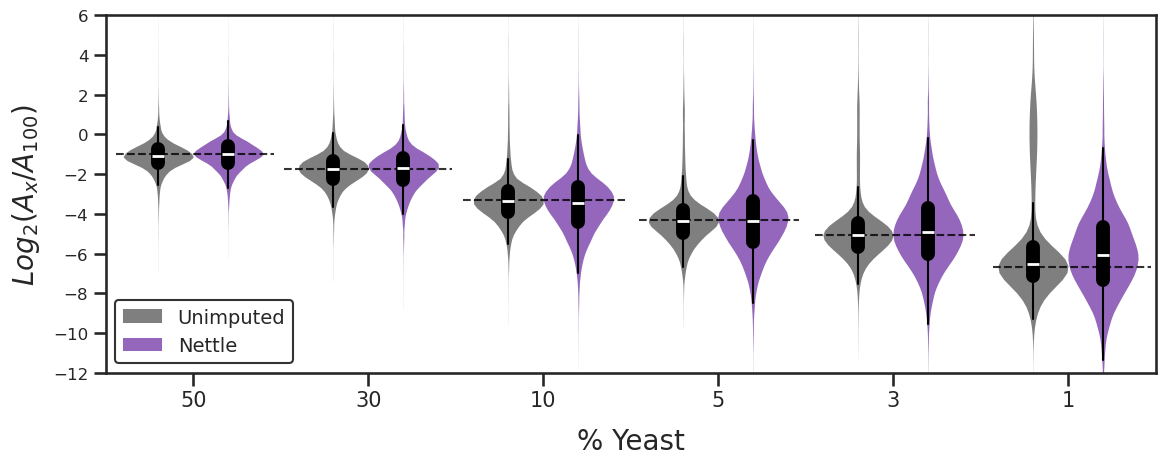

In [20]:
percent_yeast = [50, 30, 10, 5, 3, 1]
order = ["Unimputed", "Nettle"]

fig, ax = plt.subplots(figsize=(12,5))

plt.axhline(y=-1, xmin=0.01, xmax=0.16, color='black', linestyle='dashed', alpha=0.8, linewidth=1.5) #50
plt.axhline(y=-1.74, xmin=0.17, xmax=0.33, color='black', linestyle='dashed', alpha=0.8, linewidth=1.5) #30
plt.axhline(y=-3.32, xmin=0.34, xmax=0.494, color='black', linestyle='dashed', alpha=0.8, linewidth=1.5) #10
plt.axhline(y=-4.32, xmin=0.5075, xmax=0.66, color='black', linestyle='dashed', alpha=0.8, linewidth=1.5) #5
plt.axhline(y=-5.06, xmin=0.675, xmax=0.8275, color='black', linestyle='dashed', alpha=0.8, linewidth=1.5) #3
plt.axhline(y=-6.65, xmin=0.845, xmax=0.995, color='black', linestyle='dashed', alpha=0.8, linewidth=1.5) #1

sns.violinplot(
    data=plotter, 
    x="sample", y="quant", 
    palette=cmap_cust, 
    fill=True, 
    saturation=1.0,
    inner="box",
    density_norm="width",
    inner_kws=dict(box_width=10, whis_width=1.5, linewidth=1.0),
    edgecolor="black", 
    linewidth=0.01, 
    hue="method",
    hue_order=order,
)
plt.xlabel("% Yeast", labelpad=12, size=20)
plt.ylabel("$Log_{2}(A_{x}/A_{100}$)", labelpad=8, size=20)

ax.set_xticklabels(percent_yeast)
ax.tick_params(axis='x', which='major', labelsize=15)
ax.tick_params(axis='y', which='major', labelsize=12)

#plt.legend(edgecolor="black", prop={"size":12}, bbox_to_anchor=(1.01, 1.0))
plt.legend(edgecolor="black", prop={"size":14}, loc="lower left")

plt.ylim(-12, 6)

plt.tight_layout()
#plt.savefig("../figures/calcurves-just-nettle.png", dpi=350, bbox_inches="tight")
#plt.savefig("../figures/calcurves-just-nettle.pdf", bbox_inches="tight")

---
## Plot the number of quantitative peptides at each dilution 

Maybe this could become a panel for the figure. 

#### Get the number of quant. peptides for unimputed vs Nettle

In [21]:
unimputed_pvs = np.count_nonzero(~np.isnan(unimputed_df_mean), axis=0)
ensembled_pvs = np.count_nonzero(~np.isnan(ensembled_df_mean), axis=0)

peptides_plotter = pd.DataFrame(columns=["Unimputed", "Nettle", "frac"])
peptides_plotter["Unimputed"] = unimputed_pvs
peptides_plotter["Nettle"] = ensembled_pvs
peptides_plotter["frac"] = [50, 30, 10, 5, 3, 1]

peptides_plotter_melt = peptides_plotter.melt(id_vars="frac")

#### Generate bar plot

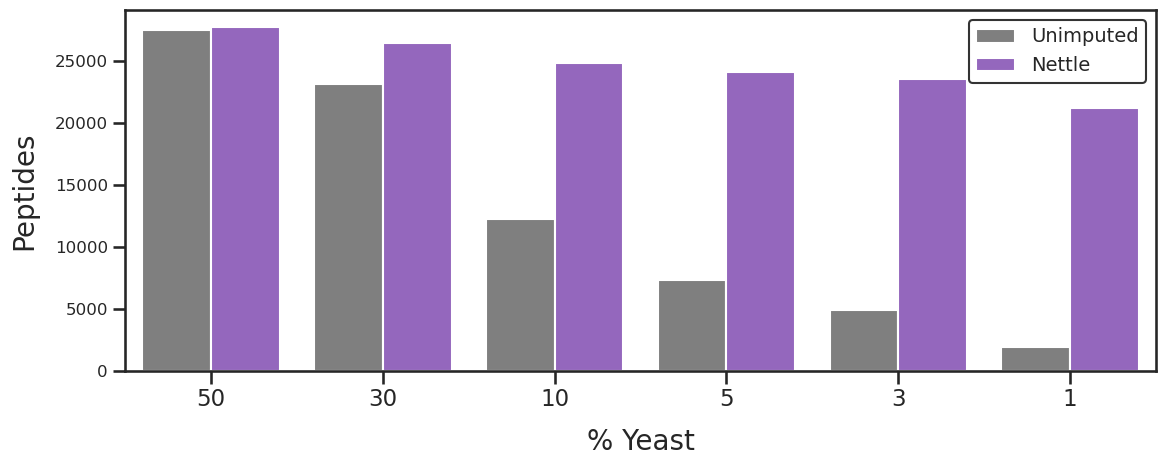

In [23]:
fig, ax = plt.subplots(figsize=(12,5))

sns.barplot(
    data=peptides_plotter_melt, 
    x="frac", y="value", 
    hue="variable",
    palette=cmap_cust, 
    saturation=1.0,
    order=[50, 30, 10, 5, 3, 1],
)

plt.xlabel("% Yeast", labelpad=12, size=20)
plt.ylabel("Peptides", labelpad=12, size=20)

#ax.set_xticklabels(percent_yeast)
#ax.tick_params(axis='x', which='major', labelsize=15)
ax.tick_params(axis='y', which='major', labelsize=12)

#leg = plt.legend(edgecolor="black", prop={"size":12}, bbox_to_anchor=(1.01, 1.0))
plt.legend(edgecolor="black", prop={"size":14}, loc="upper right")
#leg.remove()

plt.tight_layout()
#plt.savefig("../figures/CalCurves-MMCC-log-FC-plot.png", dpi=350, bbox_inches="tight")
#plt.savefig("../figures/calcurves-n-peptides-plot.pdf", bbox_inches="tight")

---
## Distributions of the imputed quants 

#### First re-ensemble Nettle and Cortado 

In [24]:
nettle_arr = np.array(nettle_df_mean_orig)
cortado_arr = np.array(cortado_df_mean_orig)

mean_arr = np.average([nettle_arr, cortado_arr], weights=[0.5, 0.5], axis=0)
ensembled_df_mean_orig = pd.DataFrame(
                            mean_arr, 
                            index=nettle_df_mean_orig.index, 
                            columns=nettle_df_mean_orig.columns,
)

ensembled_df_mean_orig = np.log(ensembled_df_mean_orig)
unimputed_df_mean_orig = np.log(unimputed_df_mean_orig)

#### Isolate the imputed and unimputed quants for a single dilution 

In [25]:
nettle_quants_arr = np.array(ensembled_df_mean_orig["E"])
unimputed_quants_arr = np.array(unimputed_df_mean_orig["E"])

mask = np.isnan(unimputed_quants_arr)
unimputed_quants = unimputed_quants_arr[~mask]
nettle_imputed_quants = nettle_quants_arr[mask]

#### Make a dataframe for plotting 

In [26]:
# First add some padding
npad = len(nettle_imputed_quants) - len(unimputed_quants)
toadd = np.zeros(npad)
toadd[:] = np.nan

unimputed_quants = np.concatenate([unimputed_quants, toadd])

quants_plotter = pd.DataFrame(columns=["Unimputed", "Nettle"])
quants_plotter["Unimputed"] = unimputed_quants
quants_plotter["Nettle"] = nettle_imputed_quants

quants_plotter_melt = quants_plotter.melt()

#### Plot histogram 

No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.


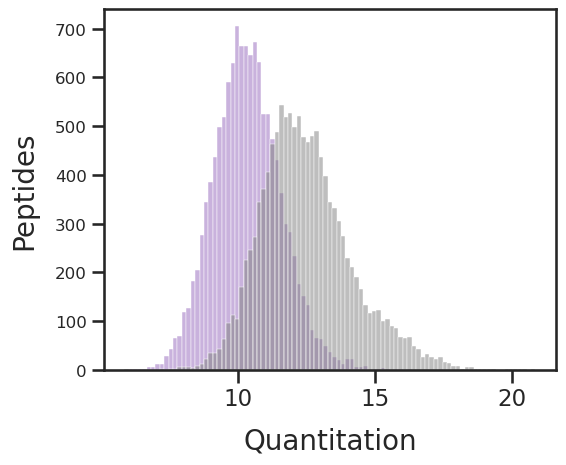

In [27]:
fig, ax = plt.subplots(figsize=(6,5))

sns.histplot(
    data=quants_plotter_melt,
    x="value", 
    hue="variable",
    palette=cmap_cust, 
)

plt.xlabel("Quantitation", labelpad=12, size=20)
plt.ylabel("Peptides", labelpad=12, size=20)

#ax.set_xticklabels(percent_yeast)
#ax.tick_params(axis='x', which='major', labelsize=15)
ax.tick_params(axis='y', which='major', labelsize=12)

leg = plt.legend(edgecolor="black", prop={"size":12}, bbox_to_anchor=(1.01, 1.0))
#plt.legend(edgecolor="black", prop={"size":14}, loc="upper right")
leg.remove()

plt.tight_layout()
#plt.savefig("../figures/peptide-distributions-plot.png", dpi=350, bbox_inches="tight")
#plt.savefig("../figures/peptide-distributions-plot.pdf", bbox_inches="tight")